# Check the baseline first: predicting running distance from Runkeeper data

The original version of this project trained a neural network to predict the distance of a workout from its other recorded fields. It reached a test MSE of 0.52 km² (0.94 km² in the seeded rerun below). This notebook asks the question that should have come first: **what does the simplest possible model score?**

Data: `cardioActivities.csv`, 508 workouts (2012–2018) exported from the Runkeeper app, from DataCamp's *Analyze Your Runkeeper Fitness Data* project.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style='whitegrid')
SEED = 42

def to_seconds(duration):
    parts = [int(p) for p in duration.split(':')]
    return parts[0] * 60 + parts[1] if len(parts) == 2 else parts[0] * 3600 + parts[1] * 60 + parts[2]

df = pd.read_csv('data/cardioActivities.csv', parse_dates=['Date'])
df['Duration (s)'] = df['Duration'].map(to_seconds)
df['Type'].value_counts()

Type
Running    459
Cycling     29
Walking     18
Other        2
Name: count, dtype: int64

## 1. The original model, reproduced

This uses the same features, preprocessing and network as the original notebook: mean-imputed heart rate, one-hot activity type, MinMax scaling, five hidden layers of 10 ReLU units, and a 70/30 split with `random_state=42`.

In [2]:
features = df[['Duration (s)', 'Average Speed (km/h)', 'Calories Burned', 'Climb (m)',
                'Average Heart Rate (bpm)', 'Type']].copy()
features['Average Heart Rate (bpm)'] = features['Average Heart Rate (bpm)'].fillna(
    features['Average Heart Rate (bpm)'].mean())
X = pd.get_dummies(features, columns=['Type']).astype(float)
y = df['Distance (km)']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED)

import logging
logging.getLogger('tensorflow').setLevel(logging.ERROR)
import tensorflow as tf
tf.keras.utils.set_random_seed(SEED)
scaler = MinMaxScaler().fit(X_train)
net = tf.keras.Sequential([tf.keras.Input(shape=(X.shape[1],))]
                          + [tf.keras.layers.Dense(10, activation='relu') for _ in range(5)]
                          + [tf.keras.layers.Dense(1)])
net.compile(optimizer='adam', loss='mse')
net.fit(scaler.transform(X_train), y_train, batch_size=16, epochs=500, verbose=0)
mse_net = mean_squared_error(y_test, net.predict(scaler.transform(X_test), verbose=0).ravel())
print(f'Neural network test MSE: {mse_net:.3f} km²')

Neural network test MSE: 0.941 km²


## 2. The baseline: distance = speed × time

Two of the inputs are average speed and duration. Their product *is* the distance. No model needs to be trained for it.

In [3]:
formula = X_test['Average Speed (km/h)'] * X_test['Duration (s)'] / 3600
linear = LinearRegression().fit(X_train, y_train)

results = pd.DataFrame({
    'test MSE (km²)': [mean_squared_error(y_test, formula),
                       mean_squared_error(y_test, linear.predict(X_test)), mse_net],
}, index=['speed × duration (no training)', 'linear regression', 'neural network (original)'])
results['× worse than formula'] = (results['test MSE (km²)'] / results['test MSE (km²)'].iloc[0]).map('{:,.0f}×'.format)
results['test MSE (km²)'] = results['test MSE (km²)'].map('{:.5f}'.format)
results

,test MSE (km²),× worse than formula
speed × duration (no training),0.00002,1×
linear regression,0.74642,"38,897×"
neural network (original),0.94117,"49,046×"


The formula's small error is only Runkeeper rounding speed and duration for display. The network is not learning anything about running. It is approximating a multiplication it was given the parts of, and doing so badly. The original notebook's prediction for a hand-made example workout (**1,416 km**) also failed, because the example's columns were listed in a different order from the training data.

## 3. The other columns are derived too

Calories are not measured either. For runs, Runkeeper's estimate is almost exactly proportional to distance. The early records also contain obvious data-entry errors, some reporting millions of kilocalories.

Runs: median 70.4 kcal/km, 90% between 66.6 and 74.1
Records with > 1,000 kcal/km (data errors): 5


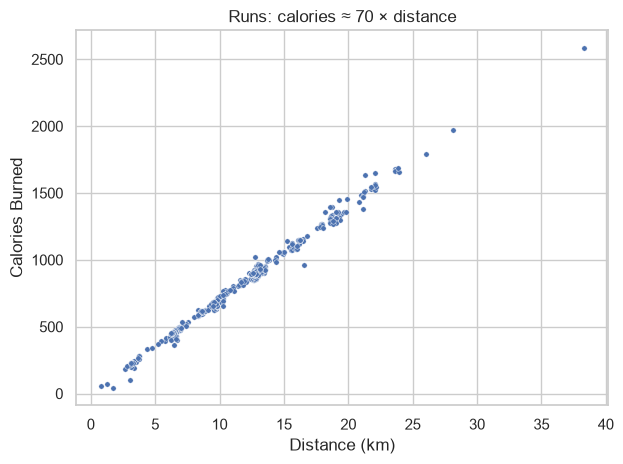

In [4]:
runs = df[df['Type'] == 'Running']
kcal_per_km = runs['Calories Burned'] / runs['Distance (km)']
print(f"Runs: median {kcal_per_km.median():.1f} kcal/km, 90% between "
      f"{kcal_per_km.quantile(.05):.1f} and {kcal_per_km.quantile(.95):.1f}")
print(f"Records with > 1,000 kcal/km (data errors): {(df['Calories Burned'] / df['Distance (km)'] > 1000).sum()}")

ok = runs[kcal_per_km < 1000]
ax = sns.scatterplot(data=ok, x='Distance (km)', y='Calories Burned', s=15)
ax.set_title('Runs: calories ≈ 70 × distance'); plt.tight_layout(); plt.show()

## 4. A target that is actually measured: heart rate

Average heart rate comes from a chest-strap sensor, and it is the one column that is not computed from the others. It is recorded for 277 runs (2015–2018). Can pace, distance, climb, duration and date predict it? The comparison below uses 5-fold CV against a model that always predicts the mean.

In [5]:
hr = runs.dropna(subset=['Average Heart Rate (bpm)']).copy()
hr['Years since 2015'] = (hr['Date'] - pd.Timestamp('2015-01-01')).dt.days / 365.25
X_hr = hr[['Distance (km)', 'Average Speed (km/h)', 'Climb (m)', 'Duration (s)', 'Years since 2015']]
y_hr = hr['Average Heart Rate (bpm)']
cv = KFold(5, shuffle=True, random_state=SEED)

rows = {}
for name, model in [('mean (baseline)', DummyRegressor()), ('linear regression', LinearRegression()),
                    ('gradient boosting', GradientBoostingRegressor(random_state=SEED))]:
    s = cross_validate(model, X_hr, y_hr, cv=cv, scoring=('neg_mean_absolute_error', 'r2'))
    rows[name] = {'MAE (bpm)': f"{-s['test_neg_mean_absolute_error'].mean():.2f} ± {s['test_neg_mean_absolute_error'].std():.2f}",
                  'R²': f"{s['test_r2'].mean():.3f} ± {s['test_r2'].std():.3f}"}
pd.DataFrame(rows).T

,MAE (bpm),R²
mean (baseline),5.76 ± 0.72,-0.009 ± 0.011
linear regression,5.28 ± 0.69,0.031 ± 0.193
gradient boosting,5.04 ± 0.94,0.004 ± 0.451


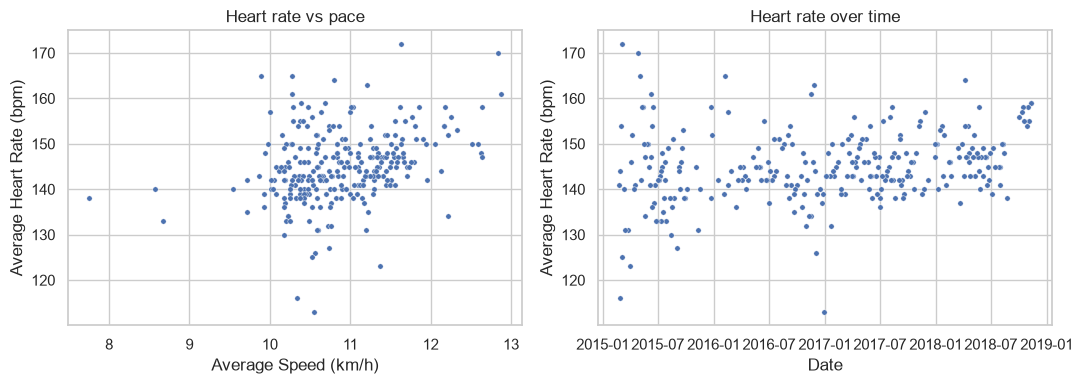

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=hr, x='Average Speed (km/h)', y='Average Heart Rate (bpm)', s=15, ax=axes[0])
sns.scatterplot(data=hr, x='Date', y='Average Heart Rate (bpm)', s=15, ax=axes[1])
axes[0].set_title('Heart rate vs pace'); axes[1].set_title('Heart rate over time')
plt.tight_layout(); plt.show()

Neither model beats the mean by a meaningful margin. Heart rate varies by only about ±8 bpm across these runs, and what drives it (weather, fatigue, terrain profile, interval structure) is not in the export.

## Takeaways

1. **Compute the trivial baseline before training anything.** Here a one-line formula beats the neural network by four orders of magnitude.
2. **Know how each column is produced.** Distance, speed, duration and calories are deterministic functions of the GPS track. Predicting one from the others is target leakage by construction.
3. **The only measured signal is not predictable from this export.** Answering a real question about heart rate would need richer data, such as per-second GPX tracks, weather or training load.